# 2.09. Другие базовые оценщики

**План занятия**

1. Propensity score и взвешивание по обратной вероятности.
2. Мэтчинг и проклятие размерности.
3. Difference-in-Differences.
4. Синтетический контроль и вывод на основе плацебо.
5. Панельные данные и фиксированные эффекты.

### Библиотеки

Для раздела о панельных данных нужен `linearmodels`. В Colab его можно поставить командой `!pip install -q linearmodels`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from ipywidgets import FloatSlider, IntSlider, interact
from linearmodels.datasets import wage_panel
from linearmodels.panel import PanelOLS
from scipy.optimize import fmin_slsqp
from scipy.special import expit
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import NearestNeighbors

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

BLUE, RED, GREEN, GRAY = '#4C72B0', '#C44E52', '#55A868', '#7F7F7F'
DATA = 'data/'
rng = np.random.default_rng(42)

## Напоминание: потенциальные исходы

В лекции 2.08 мы разобрали основы, поэтому здесь только напомним их.

**[Корреляция не означает причинность](https://en.wikipedia.org/wiki/Correlation_does_not_imply_causation)**. Для каждой единицы $i$ есть два потенциальных исхода: $Y_{1i}$ с воздействием и $Y_{0i}$ без него. Наблюдаем мы только один:

$$Y_i = Y_{1i} T_i + Y_{0i} (1 - T_i)$$

Поэтому оценивают средние эффекты: $ATE = E[Y_1 - Y_0]$ и $ATT = E[Y_1 - Y_0 \mid T = 1]$. Простая разница средних содержит смещение:

$$
E[Y|T=1] - E[Y|T=0] = \underbrace{E[Y_1 - Y_0|T=1]}_{ATT} + \underbrace{E[Y_0|T=1] - E[Y_0|T=0]}_{BIAS}
$$

Рандомизация убирает смещение. Эта лекция о методах для случаев, когда рандомизации нет или она нарушена.

| Метод | Нужно предположить |
| :--- | :--- |
| Propensity score, мэтчинг | Все конфаундеры измерены: $(Y_0, Y_1) \perp T \mid X$ |
| Difference-in-Differences | Без воздействия тренды групп были бы параллельны |
| Синтетический контроль | Комбинация контрольных единиц воспроизводит контрфактический исход |
| Фиксированные эффекты | Конфаундеры не меняются во времени |

## Propensity Score

### Психология роста

Позитивная психология изучает, какое поведение способствует успешной жизни. Одна из её известных идей — **мышление роста**. Человек с фиксированным мышлением считает, что способности даны от рождения и не меняются. Человек с мышлением роста считает, что интеллект можно развить, и воспринимает неудачи как часть обучения. Психологи обнаружили, что люди с мышлением роста обычно добиваются большего.

Но нас интересует причинность. Побуждает ли мышление роста достигать большего, или успешные люди развивают его благодаря успеху? В терминах потенциальных исходов $E[Y_0|T=1]$, вероятно, больше $E[Y_0|T=0]$: те, кто выбрал мышление роста, добились бы большего и с фиксированным мышлением.

Чтобы разобраться, исследователи провели [Национальное исследование установок на обучение](https://mindsetscholarsnetwork.org/about-the-network/current-initatives/national-mindset-study/#). Это рандомизированное исследование в государственных старших школах США: учащиеся посещают семинар, а затем отслеживается их успеваемость. Показатель объединён в стандартизированный балл. Реальные данные закрыты, поэтому мы используем смоделированный набор с теми же статистическими свойствами от [Athey and Wager](https://arxiv.org/pdf/1902.07409.pdf).

In [2]:
data = pd.read_csv(DATA + 'propensity_score_df.csv')
print(f"Учеников: {len(data)}, школ: {data['schoolid'].nunique()}, доля посетивших семинар: {data['intervention'].mean():.3f}")
data.sample(5, random_state=5).iloc[:, :8]

Учеников: 10391, школ: 76, доля посетивших семинар: 0.326


,schoolid,intervention,achievement_score,success_expect,ethnicity,gender,frst_in_family,school_urbanicity
259,73,1,1.480828,5,1,2,0,1
3435,76,0,-0.987277,5,13,1,1,4
9963,4,0,-0.152340,5,2,2,1,0
4488,67,0,0.358336,6,14,1,0,4
2637,16,1,1.360920,6,4,1,0,1


Хотя исследование рандомизированное, данные не лишены смещения. Воздействие здесь — это факт посещения семинара. Возможность была случайной, а участие нет. Это несоблюдение назначения из лекции 2.08: посещали чаще те, кто сам ожидает успеха.

In [3]:
print(data.groupby('success_expect')['intervention'].mean().round(3))
naive = data.query('intervention == 1')['achievement_score'].mean() - data.query('intervention == 0')['achievement_score'].mean()
print('Наивная разница средних:', round(naive, 3))

success_expect
1    0.272
2    0.266
3    0.294
4    0.272
5    0.311
6    0.354
7    0.362
Name: intervention, dtype: float64
Наивная разница средних: 0.472


Предположим, что все конфаундеры измерены: $(Y_1, Y_0) \perp T | X$. Тогда не обязательно контролировать весь вектор $X$. Достаточно одной переменной — вероятности воздействия при данных признаках, которая называется **propensity score**:

$$
e(x) = P(T=1|X=x), \qquad (Y_1, Y_0) \perp T | e(x)
$$

Можно считать $e(x)$ промежуточным звеном между $X$ и $T$.

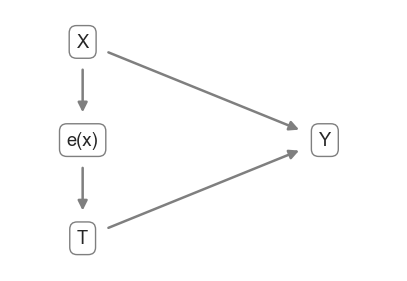

In [4]:
pos = {'X': (0, 1), 'e(x)': (0, 0.4), 'T': (0, -0.2), 'Y': (1, 0.4)}
fig, ax = plt.subplots(figsize=(5, 3.4))
ax.set_axis_off()
for start, end in [('X', 'e(x)'), ('e(x)', 'T'), ('X', 'Y'), ('T', 'Y')]:
    ax.annotate('', xy=pos[end], xytext=pos[start], arrowprops=dict(arrowstyle='-|>', lw=1.8, color=GRAY, shrinkA=20, shrinkB=20, mutation_scale=14))
for name, (x, y) in pos.items():
    ax.text(x, y, name, ha='center', va='center', bbox=dict(boxstyle='round,pad=0.4', fc='white', ec=GRAY))
ax.set_xlim(-0.3, 1.3)
ax.set_ylim(-0.4, 1.2);

Если мы знаем $e(x)$, то $X$ больше ничего не говорит о $T$. В нашем примере амбициозные чаще посещают семинар и больше добиваются. Но если взять двух учеников с одинаковой вероятностью участия, то при измеренных конфаундерах один попал на семинар, а другой нет только случайно.

Докажем это в два шага (Розенбаум и Рубин, 1983). Сначала покажем **балансирующее свойство**: $T \perp X | e(x)$. Поскольку $e(x)$ — функция от $X$, $E[T|e(x), X] = E[T|X] = e(x)$. А по [закону итерированных ожиданий](https://en.wikipedia.org/wiki/Law_of_total_expectation)

$$
E[T|e(x)] = E\big[E[T|e(x),X] \,\big|\, e(x)\big] = E[e(x)|e(x)] = e(x)
$$

Значит, $E[T|e(x), X] = E[T|e(x)]$.

Теперь добавим предположение о несмешиваемости. Для бинарного $T$ независимость означает, что вероятность воздействия не зависит от потенциальных исходов:

$$
P(T=1|Y_1,Y_0,e(x)) = E\big[P(T=1|Y_1,Y_0,X) \,\big|\, Y_1,Y_0,e(x)\big] = E\big[e(x) \,\big|\, Y_1,Y_0,e(x)\big] = e(x)
$$

Среднее равенство использует $(Y_1, Y_0) \perp T | X$. Если конфаундер не измерен, propensity score от него не спасёт: скор балансирует только $X$, вошедшие в модель.

Запишем условную разность средних через $e(x)$:

$$
E[Y|X,T=1]-E[Y|X,T=0] = E\bigg[\dfrac{YT}{e(x)}\bigg|X\bigg] - E\bigg[\dfrac{Y(1-T)}{1-e(x)}\bigg|X\bigg]
$$

Первое слагаемое оценивает $Y_1$: берёт получивших воздействие и взвешивает их на обратную вероятность. Тот, кто получил воздействие при низкой вероятности, похож на контрольных, поэтому его вес большой. Второе слагаемое делает то же для контрольных. Метод называется **взвешиванием по обратной вероятности воздействия (IPTW)**.

Упростим выражение:

$$
\begin{align}
E\bigg[\dfrac{YT}{e(x)} - \dfrac{Y(1-T)}{1-e(x)}\bigg|X\bigg]
&=E\bigg[Y\dfrac{T(1-e(x)) - e(x)(1-T)}{e(x)(1-e(x))}\bigg|X\bigg] \\
&=E\bigg[Y \dfrac{T-e(x)}{e(x)(1-e(x))}\bigg|X\bigg]
\end{align}
$$

Усреднив по $X$, получим $ATE = E\big[Y \frac{T-e(x)}{e(x)(1-e(x))}\big]$. Формула работает, только если $0 < e(x) < 1$. Это **условие перекрытия (positivity)**: при близких к 0 или 1 скорах веса взрываются.

Истинная $e(x)$ неизвестна, поэтому её заменяют оценкой $\hat{e}(x)$. Обычно используют логистическую регрессию. Можно и бустинг, но нужна кросс-валидация и контроль за переобучением: идеально предсказанное воздействие даст скоры 0 и 1.

In [5]:
categ = ['ethnicity', 'gender', 'school_urbanicity']
features = pd.get_dummies(data.drop(columns=['schoolid', 'intervention', 'achievement_score']), columns=categ).astype(float)

T = data['intervention'].to_numpy()
Y = data['achievement_score'].to_numpy()

ps_model = LogisticRegression(C=1e6, max_iter=2000).fit(features, T)
data_ps = data.assign(propensity_score=ps_model.predict_proba(features)[:, 1])
e = data_ps['propensity_score'].to_numpy()

data_ps[['intervention', 'achievement_score', 'propensity_score']].head()

,intervention,achievement_score,propensity_score
0,1,0.277359,0.315271
1,1,-0.449646,0.263482
2,1,0.769703,0.343781
3,1,-0.121763,0.343781
4,1,1.526147,0.367474


In [6]:
weights = T / e + (1 - T) / (1 - e)
print('Размер выборки:', len(data))
print('Сумма весов получивших воздействие:', round((T / e).sum(), 1))
print('Сумма весов контроля:', round(((1 - T) / (1 - e)).sum(), 1))
print('Максимальный вес:', round(weights.max(), 2))

Размер выборки: 10391
Сумма весов получивших воздействие: 10387.6
Сумма весов контроля: 10391.5
Максимальный вес: 6.15


Обе взвешенные группы примерно равны исходной выборке: каждая стала псевдопопуляцией размером со всю выборку.

Перед оценкой эффекта проверяем две вещи. Первая — **перекрытие**: распределения скора в группах должны пересекаться. Вторая — **баланс**: после взвешивания признаки должны совпасть. Для этого используют стандартизированную разность средних (SMD); обычно хотят $|SMD| < 0.1$.

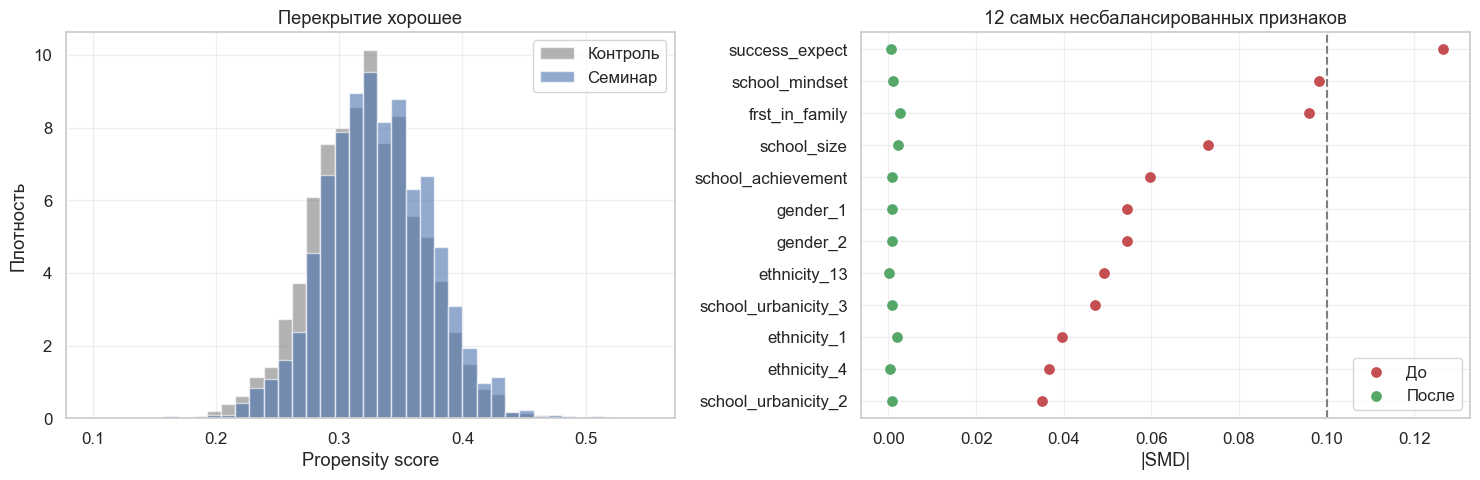

In [7]:
def standardized_difference(column, w):
    treated, control = T == 1, T == 0
    pooled_sd = np.sqrt((column[treated].var() + column[control].var()) / 2)
    return (np.average(column[treated], weights=w[treated]) - np.average(column[control], weights=w[control])) / pooled_sd


balance = pd.DataFrame({'До взвешивания': [standardized_difference(features[c].to_numpy(), np.ones(len(T))) for c in features],
                        'После взвешивания': [standardized_difference(features[c].to_numpy(), weights) for c in features]},
                       index=features.columns)
balance = balance.reindex(balance['До взвешивания'].abs().sort_values().index).tail(12)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
bins = np.linspace(0.1, 0.55, 40)
axes[0].hist(e[T == 0], bins=bins, color=GRAY, alpha=0.6, density=True, label='Контроль')
axes[0].hist(e[T == 1], bins=bins, color=BLUE, alpha=0.6, density=True, label='Семинар')
axes[0].set_xlabel('Propensity score')
axes[0].set_ylabel('Плотность')
axes[0].set_title('Перекрытие хорошее')
axes[0].legend()

y = np.arange(len(balance))
axes[1].scatter(balance['До взвешивания'].abs(), y, color=RED, s=45, label='До')
axes[1].scatter(balance['После взвешивания'].abs(), y, color=GREEN, s=45, label='После')
axes[1].axvline(0.1, color=GRAY, ls='--')
axes[1].set_yticks(y, balance.index)
axes[1].set_xlabel('|SMD|')
axes[1].set_title('12 самых несбалансированных признаков')
axes[1].legend()
plt.tight_layout()

In [8]:
y1 = np.mean(T * Y / e)
y0 = np.mean((1 - T) * Y / (1 - e))
ate = np.mean(Y * (T - e) / (e * (1 - e)))

print('Y1:', round(y1, 4))
print('Y0:', round(y0, 4))
print('ATE:', round(ate, 4))
print('Наивная разница:', round(naive, 4))
design = np.column_stack([T, np.ones(len(T)), features.to_numpy()])
print('Регрессия с теми же признаками:', round(np.linalg.lstsq(design, Y, rcond=None)[0][0], 4))

Y1: 0.2598
Y0: -0.129
ATE: 0.3888
Наивная разница: 0.4723
Регрессия с теми же признаками: 0.3937


Посещение семинара повышает успеваемость на 0.39 стандартного отклонения против наивных 0.47. Если бы никто не посещал семинар, средний балл был бы на 0.13 ниже текущего, а если бы посещали все — на 0.26 выше. Регрессия с теми же признаками даёт почти то же самое. Это естественно: у неё то же предположение, что все конфаундеры измерены.

Нужен ещё интервал. Формула SE здесь не годится: оценён и скор, и ученики сгруппированы по школам. Поэтому используем бутстреп, который на каждой итерации заново учит скор и выбирает школы целиком.

In [9]:
def iptw_ate(t, y, x):
    score = LogisticRegression(C=1e6, max_iter=2000).fit(x, t).predict_proba(x)[:, 1]
    return np.mean(y * (t - score) / (score * (1 - score)))


school_rows = [np.flatnonzero(data['schoolid'].to_numpy() == school) for school in data['schoolid'].unique()]
x_matrix = features.to_numpy()
boot_rng = np.random.default_rng(0)

boot = []
for _ in range(200):
    rows = np.concatenate([school_rows[i] for i in boot_rng.integers(0, len(school_rows), len(school_rows))])
    boot.append(iptw_ate(T[rows], Y[rows], x_matrix[rows]))

print(f'ATE = {ate:.3f}, SE = {np.std(boot):.3f}, 95% ДИ [{np.percentile(boot, 2.5):.3f}, {np.percentile(boot, 97.5):.3f}]')

ATE = 0.389, SE = 0.026, 95% ДИ [0.335, 0.438]


Интервал не включает наивную оценку 0.47, то есть смещение здесь реальное. В этих данных перекрытие хорошее, максимальный вес около 6. Посмотрим, что происходит, когда оно плохое. Подвигайте силу отбора: чем она больше, тем сильнее воздействие определяется признаком $X$. Настоящий эффект равен 1.

**Эффективный размер выборки (ESS)** $= (\sum w_i)^2 / \sum w_i^2$ показывает, скольким обычным наблюдениям равна взвешенная выборка.

In [10]:
def simulate_iptw(strength, n=4000, seed=1):
    """Сравнивает наивную оценку и IPTW при известном эффекте 1."""
    local = np.random.default_rng(seed)
    x = local.normal(0, 1, n)
    score = expit(strength * x)
    t = local.random(n) < score
    y = 2 * x + t + local.normal(0, 1, n)
    w = np.where(t, 1 / score, 1 / (1 - score))
    return {'x': x, 't': t, 'score': score, 'naive': y[t].mean() - y[~t].mean(),
            'iptw': np.mean(y * (t - score) / (score * (1 - score))), 'ess': w.sum() ** 2 / (w ** 2).sum(), 'max_w': w.max()}


def plot_iptw(ax, strength):
    r = simulate_iptw(strength)
    bins = np.linspace(0, 1, 31)
    ax.hist(r['score'][~r['t']], bins=bins, color=GRAY, alpha=0.6, label='Контроль')
    ax.hist(r['score'][r['t']], bins=bins, color=BLUE, alpha=0.6, label='Воздействие')
    ax.set_title(f"Сила {strength}: наивно {r['naive']:.2f}, IPTW {r['iptw']:.2f}\nESS {r['ess']:.0f}, макс. вес {r['max_w']:.0f}", fontsize=12)
    ax.set_xlabel('Propensity score')


def iptw_demo(strength=1.0):
    fig, ax = plt.subplots(figsize=(8, 4.2))
    plot_iptw(ax, strength)
    ax.legend()
    plt.show()


interact(iptw_demo, strength=FloatSlider(value=1, min=0, max=6, step=0.5, description='Сила отбора'));

Статичная версия для четырёх значений силы отбора.

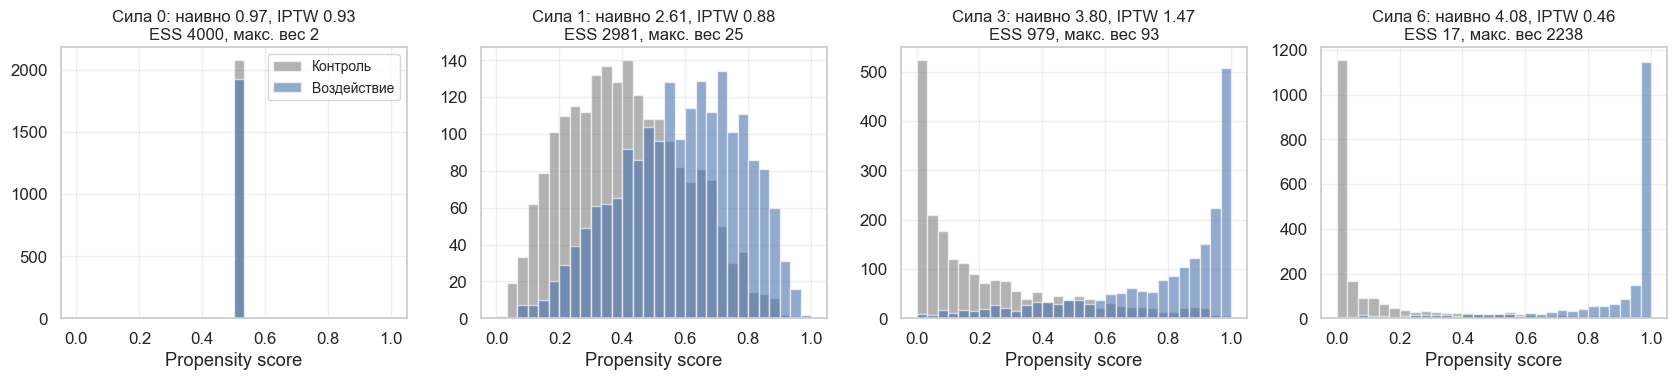

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4), sharex=True)
for ax, strength in zip(axes, [0, 1, 3, 6]):
    plot_iptw(ax, strength)
axes[0].legend(fontsize=10)
plt.tight_layout()

Наивная оценка растёт с силой отбора от 1 до 4. При умеренном отборе IPTW работает, хотя и шумно. При силе 3 оценка уже 1.47, а при силе 6 равна 0.46: ESS упал с 4000 до 17, и всё держится на нескольких объектах с весами в сотни и тысячи. Формула здесь формально верна, но такой результат нельзя использовать. На практике тогда обрезают скоры или веса, сужают выборку до зоны перекрытия либо используют взвешивание с перекрытием. Важно помнить, что после этого оценивается эффект не для всей популяции.

## Мэтчинг

Если выполнена условная независимость $(Y_0, Y_1)\perp T | X$, то можно считать эффект внутри небольших групп с одинаковым $X$:

$$
ATE = \int(E[Y|X, T=1] - E[Y|X, T=0])dP(x)
$$

Если признаки дискретны и занимают $K$ ячеек, интеграл превращается в сумму, которая называется оценкой подклассификации:

$$
\hat{ATE} = \sum^K_{k=1}(\bar{Y}_{k1} - \bar{Y}_{k0}) \dfrac{N_k}{N}
$$

Здесь $\bar{Y}_{k1}$ и $\bar{Y}_{k0}$ — средние исхода групп в ячейке $k$, а $N_k$ — её размер. Регрессия с бинарными контролями делает похожее, но взвешивает ячейки не по размеру, а пропорционально дисперсии воздействия в них.

**Мэтчинг** развивает эту идею: **каждому объекту теста ищем похожий контрольный объект**, как будто находим близнеца.

Процесс выглядит так:

1. Определяем меру близости объектов.
2. Подбираем пары с её учётом.
3. Проверяем баланс полученных групп и при необходимости возвращаемся к шагу 1 или 2.
4. Оцениваем разницу между группами.

Основные методы:

* **Exact Matching.** Для каждого объекта теста ищется идентичный объект в контроле. Если он нашёлся, расстояние равно 0, иначе бесконечно.
* **Coarsened Exact Matching.** Непрерывные признаки огрубляются до категорий, а затем идентичный объект ищется в этом пространстве.
* **Mahalanobis Distance Matching.** Расстояние между двумя объектами учитывает масштаб и корреляции признаков:

$$
Distance(X_c, X_t) = \sqrt{(X_c - X_t)^T S^{-1} (X_c - X_t)}
$$

где $S$ — ковариационная матрица признаков.

У этих подходов есть фундаментальная проблема — **проклятие размерности**. Легко найти совпадение по полу. Но если добавить возраст, доход и город рождения, найти близких соседей всё труднее: число точек, необходимых для заполнения пространства, растёт экспоненциально с числом признаков. Для подклассификации это значит, что в ячейках будет только тест или только контроль. Для мэтчинга — что пары будут далеки друг от друга, а это создаёт смещение.

Посмотрим на это численно: сколько в среднем до ближайшего соседа, если все признаки независимы и стандартны.

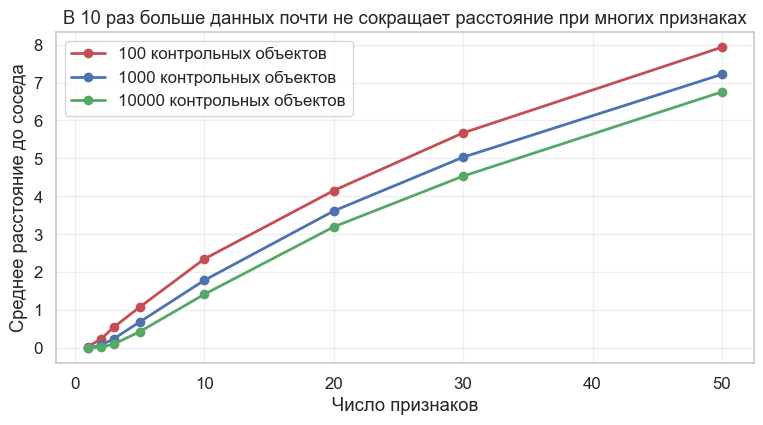

In [12]:
dimensions = [1, 2, 3, 5, 10, 20, 30, 50]
sizes = [100, 1000, 10000]

fig, ax = plt.subplots(figsize=(9, 4.3))
for size, color in zip(sizes, [RED, BLUE, GREEN]):
    distances = []
    for dim in dimensions:
        control = rng.normal(size=(size, dim))
        treated = rng.normal(size=(200, dim))
        distances.append(NearestNeighbors(n_neighbors=1).fit(control).kneighbors(treated)[0].mean())
    ax.plot(dimensions, distances, 'o-', color=color, lw=2, label=f'{size} контрольных объектов')
ax.set_xlabel('Число признаков')
ax.set_ylabel('Среднее расстояние до соседа')
ax.set_title('В 10 раз больше данных почти не сокращает расстояние при многих признаках')
ax.legend();

Большинство моделей снижают размерность. Линейная регрессия проецирует все признаки на одно направление. Похожую идею реализует **Propensity Score Matching (PSM)**: объекты сопоставляются не по $X$, а по одномерному скору.

Сопоставим каждого участника семинара с ближайшим по скору контрольным учеником. Такой мэтчинг оценивает ATT: мы находим пару для получивших воздействие. Для сравнения посчитаем и ATT по IPTW: контрольные объекты получают вес $e/(1-e)$.

In [13]:
matcher = NearestNeighbors(n_neighbors=1).fit(e[T == 0].reshape(-1, 1))
match_distance, matched = matcher.kneighbors(e[T == 1].reshape(-1, 1))
matched_control = np.flatnonzero(T == 0)[matched[:, 0]]

att_psm = (Y[T == 1] - Y[matched_control]).mean()
att_weights = (1 - T) * e / (1 - e)
att_iptw = Y[T == 1].mean() - np.sum(att_weights * Y) / att_weights.sum()

print(f'ATT по PSM:   {att_psm:.3f}')
print(f'ATT по IPTW:  {att_iptw:.3f}')
print(f'Среднее расстояние в паре: {match_distance.mean():.6f}')
print(f'Уникальных контрольных объектов: {len(np.unique(matched_control))} на {(T == 1).sum()} участников')

ATT по PSM:   0.387
ATT по IPTW:  0.396
Среднее расстояние в паре: 0.000048
Уникальных контрольных объектов: 1588 на 3384 участников


Результаты близки, но у PSM есть важные оговорки.

* Один контрольный объект здесь использован для нескольких участников, это мэтчинг с возвращением. Эффективный размер контроля меньше, чем кажется.
* [Кинг и Нильсен (2019)](https://www.cambridge.org/core/journals/political-analysis/article/abs/why-propensity-scores-should-not-be-used-for-matching/94DDE7ED8E2A796B693096EB714BE68B) показали, что PSM может ухудшать баланс. Он приближает полностью рандомизированный эксперимент, а не более эффективный блочный, и при избыточной подгонке может увеличивать дисбаланс и зависимость от модели. Поэтому баланс нужно всегда проверять на $X$, а не только на скоре.
* [Обычный бутстреп для мэтчинга некорректен (Абади и Имбенс, 2008)](https://www.econometricsociety.org/publications/econometrica/2008/11/01/On-the-Failure-of-the-Bootstrap-for-Matching-Estimators). Для SE используют аналитические формулы или подвыборки. Поэтому для мэтчинга мы не строим бутстреп-интервал.

## Difference-in-Differences

### Три рекламных щита на юге Бразилии

Онлайн-рекламу легко оценить: видно, кто её увидел и что сделал. С билбордом или телевидением сложнее. Можно измерить продажи до и после размещения, но как узнать, что рост — не естественная тенденция? Иначе говоря, как узнать контрфактический $Y_0$?

Один из методов для таких вопросов — **Difference-in-Differences**, или diff-in-diff. Его используют для оценки последствий законов, мер политики или офлайн-кампаний: есть период до и после вмешательства, а нужно отделить его влияние от общей тенденции.

Рассмотрим пример. Чтобы оценить билборды, банк разместил их на весь июнь в Порту-Алегри, столице штата Риу-Гранди-ду-Сул. Цель — рост поступлений на сберегательный счёт. В качестве контроля возьмём другую южную столицу, Флорианополис. Данные содержат май (до) и июль (после).

In [14]:
did = pd.read_csv(DATA + 'diff_in_diff_df.csv')
did.groupby(['poa', 'jul'])['deposits'].agg(['size', 'mean']).round(2)

size    mean
poa jul              
0   0    1300  171.64
    1    2000  206.17
1   0     500   46.02
    1     800   87.06

`deposits` — исход, `poa` — флаг Порту-Алегри, `jul` — флаг июля. Чтобы не путать время и воздействие, здесь $D$ обозначает воздействие, а $T$ — время. Пусть $Y_D(T)$ — потенциальный исход при воздействии $D$ в период $T$. Хотелось бы оценить

$$
ATT = E[Y_1(1) - Y_0(1)|D=1]
$$

Но $Y_0(1)$ для обработанного города мы не видим. **Difference-in-Differences** подставляет вместо него

$$
E[Y_0(1)|D=1] = E[Y_0(0)|D=1] + \big(E[Y_0(1)|D=0] - E[Y_0(0)|D=0]\big)
$$

То есть берёт обработанную группу до вмешательства и добавляет рост контрольной группы. Для этого нужно **предположение о параллельных трендах**:

$$
E[Y_0(1) - Y_0(0)|D=1] = E[Y_0(1) - Y_0(0)|D=0]
$$

Слева здесь контрфактический тренд, который мы не наблюдаем. Подставив, получим

$$
\hat{ATT} = E[Y(1)|D=1] - \big(E[Y(0)|D=1] + E[Y(1)|D=0] - E[Y(0)|D=0]\big)
$$

Если переставить члены, получится классическая оценка:

$$
\hat{ATT} = \big(E[Y(1)|D=1] - E[Y(1)|D=0]\big) - \big(E[Y(0)|D=1] - E[Y(0)|D=0]\big)
$$

Название отражает суть: это разность между разностями групп после и до вмешательства.

Это предположение слабее, чем у других подходов. Сравнение «до и после» требует отсутствия тренда, сравнение городов — равенства уровней. Diff-in-diff требует только одинаковой динамики. Разный базовый уровень допустим.

На схеме контрфактический тренд пунктирный:

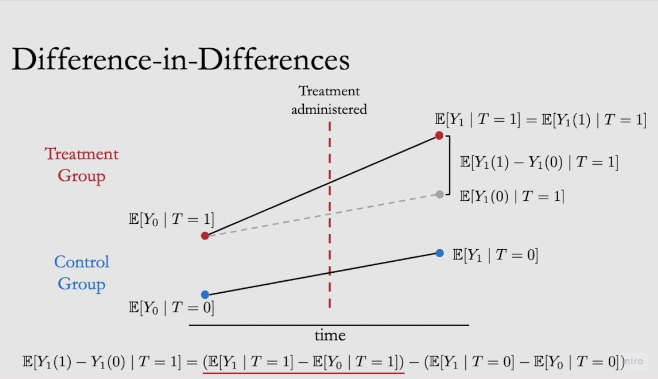

Обычно diff-in-diff оценивают линейной регрессией, опираясь на теорему:

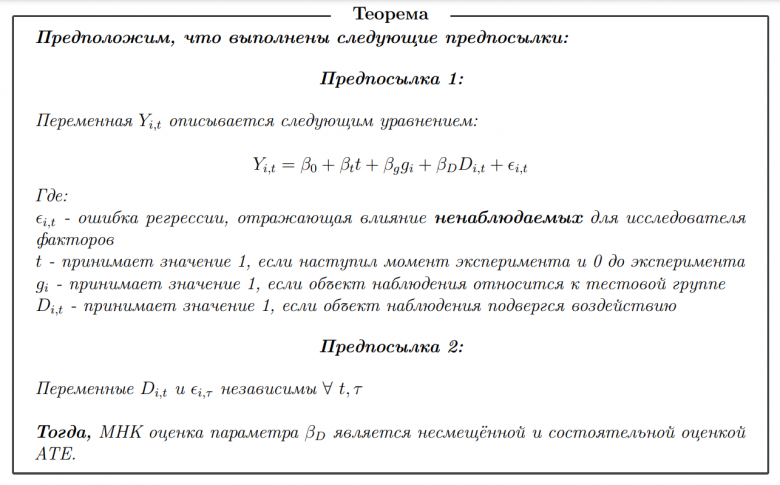

В теореме предполагается постоянный эффект, поэтому ATE и ATT совпадают. В общем случае это оценка ATT.

В нашем случае модель выглядит так:

$$
Y_i = \beta_0 + \beta_1 POA_i + \beta_2 Jul_i + \beta_3 POA_i \cdot Jul_i + e_i
$$

* $\beta_0$ — уровень депозитов во Флорианополисе в мае.
* $\beta_1$ — разница Порту-Алегри и Флорианополиса в мае.
* $\beta_2$ — тренд контрольного города.
* $\beta_3$ — дополнительный прирост в Порту-Алегри, то есть оценка diff-in-diff.

Значения средних: $\beta_0$ — контроль до, $\beta_0 + \beta_1$ — обработанный до, $\beta_0 + \beta_2$ — контроль после, а сумма всех четырёх — обработанный после.

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    171.6423      2.498     68.711      0.000     166.746     176.538
poa         -125.6263      3.075    -40.853      0.000    -131.653    -119.599
jul           34.5232      3.342     10.329      0.000      27.972      41.074
poa:jul        6.5246      4.245      1.537      0.124      -1.796      14.845
Сравнение до и после в Порту-Алегри: 41.05
Сравнение городов в июле:            -119.1
Diff-in-diff вручную:                6.52


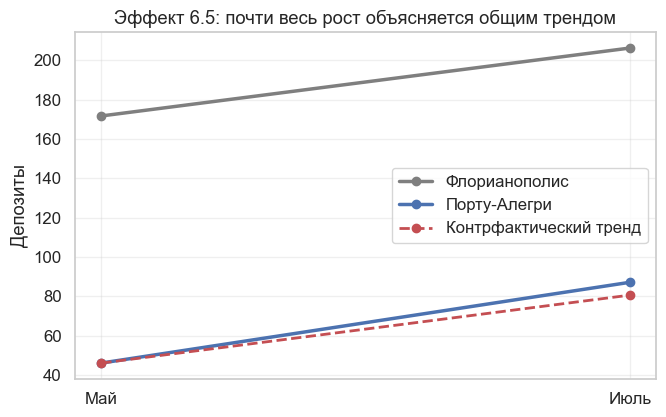

In [15]:
did_model = smf.ols('deposits ~ poa * jul', data=did).fit(cov_type='HC1')
print(did_model.summary().tables[1])

means = did.groupby(['poa', 'jul'])['deposits'].mean()
print('Сравнение до и после в Порту-Алегри:', round(means[1, 1] - means[1, 0], 2))
print('Сравнение городов в июле:           ', round(means[1, 1] - means[0, 1], 2))
print('Diff-in-diff вручную:               ', round((means[1, 1] - means[1, 0]) - (means[0, 1] - means[0, 0]), 2))

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot([0, 1], [means[0, 0], means[0, 1]], 'o-', color=GRAY, lw=2.5, label='Флорианополис')
ax.plot([0, 1], [means[1, 0], means[1, 1]], 'o-', color=BLUE, lw=2.5, label='Порту-Алегри')
ax.plot([0, 1], [means[1, 0], means[1, 0] + means[0, 1] - means[0, 0]], 'o--', color=RED, lw=2, label='Контрфактический тренд')
ax.set_xticks([0, 1], ['Май', 'Июль'])
ax.set_ylabel('Депозиты')
ax.set_title(f"Эффект {did_model.params['poa:jul']:.1f}: почти весь рост объясняется общим трендом")
ax.legend();

Сравнение до и после дало бы рост на 41, сравнение городов — падение на 119. Diff-in-diff даёт 6.5, а интервал от -1.8 до 14.8 включает ноль. Значимого эффекта билбордов мы не обнаружили.

При этом даже эта SE слишком оптимистична. Она считает независимыми тысячи клиентов, а воздействие назначено целому городу, и городов всего два. Если в Порту-Алегри в июне произошло что-то своё, данные это не отличат от эффекта билбордов. [Бертран, Дюфло и Муллайнатан (2004)](https://www.nber.org/papers/w8841) показали, что такие SE сильно занижены, и рекомендуют кластеризацию на уровне групп, которой при двух городах нет.

Главная проблема метода — параллельные тренды. Если решение о воздействии зависит от показателей, а это обычное дело, они могут нарушаться. Мы могли выбрать Порту-Алегри из-за низких продаж: тогда рост там без билборда мог быть другим, и оценка смещена. Подвигайте разницу трендов, чтобы увидеть, как это влияет на оценку. Настоящий эффект здесь равен 10.

In [16]:
def plot_did(ax, trend_gap, effect=10, pre_periods=6, post_periods=4):
    """Показывает панель, где у групп разные тренды, и оценку с двумя периодами."""
    time = np.arange(-pre_periods, post_periods)
    control = 100 + 2 * time
    treated_y0 = 60 + (2 + trend_gap) * time
    treated = treated_y0 + effect * (time >= 0)
    estimate = (treated[pre_periods] - treated[pre_periods - 1]) - (control[pre_periods] - control[pre_periods - 1])

    ax.plot(time, control, 'o-', color=GRAY, label='Контроль')
    ax.plot(time, treated, 'o-', color=BLUE, label='Тест')
    ax.plot(time[pre_periods - 1:], treated[pre_periods - 1] + (control[pre_periods - 1:] - control[pre_periods - 1]), '--', color=RED, label='Контрфактический тренд DiD')
    ax.plot(time, treated_y0, ':', color=GREEN, label='Настоящий Y0')
    ax.axvline(-0.5, color=GRAY, ls=':')
    ax.set_title(f'Разница трендов {trend_gap:+.1f}: оценка {estimate:.1f} при настоящих {effect}', fontsize=12)
    ax.set_xlabel('Период относительно вмешательства')


def did_demo(trend_gap=0.0):
    fig, ax = plt.subplots(figsize=(8.5, 4.5))
    plot_did(ax, trend_gap)
    ax.legend(fontsize=10)
    plt.show()


interact(did_demo, trend_gap=FloatSlider(value=0, min=-3, max=3, step=0.5, description='Разница'));

Статичная версия: тренды совпадают, тест растёт быстрее и тест растёт медленнее.

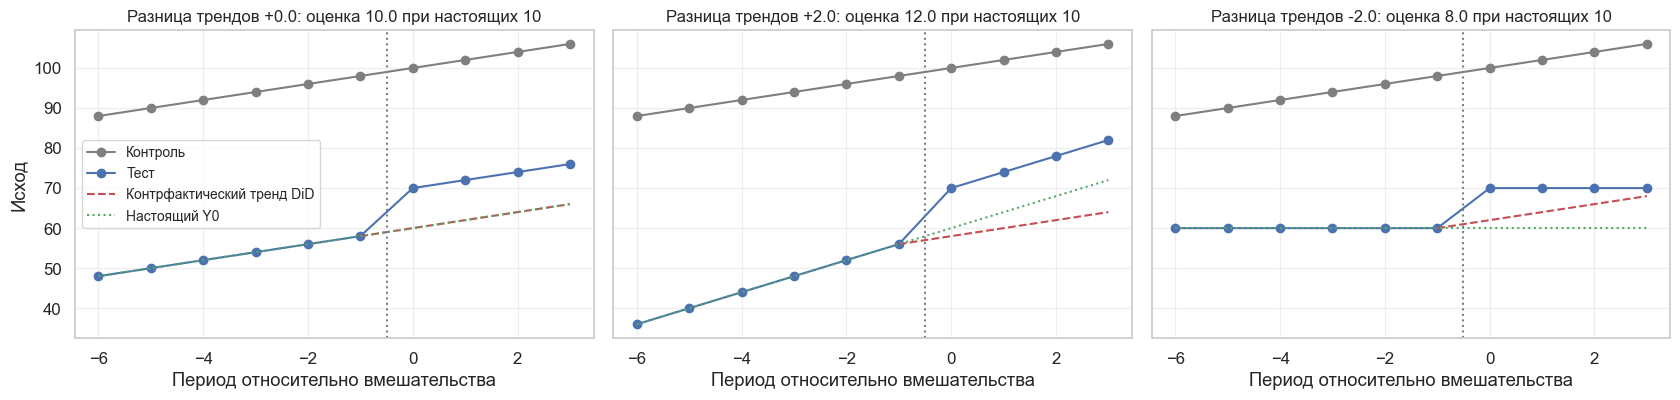

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2), sharey=True)
for ax, gap in zip(axes, [0, 2, -2]):
    plot_did(ax, gap)
axes[0].legend(fontsize=10)
axes[0].set_ylabel('Исход')
plt.tight_layout()

Каждая единица разницы трендов добавляет такую же величину к оценке. Если есть несколько периодов до вмешательства, тренды можно посмотреть на данных. Но совпадение до вмешательства не доказывает, что они совпадали бы и после. У нас два периода, и проверить нечего.

Если воздействие включается в разное время, классическая регрессия с двумя фиксированными эффектами может давать смещённую оценку (Гудман-Бэкон, 2021). Для этого есть специальные оценщики, например Каллауэй и Сант-Анна (2021).

## Синтетический контроль

Допустим, что у нас есть только агрегаты по городам:

| Город | До | После |
| :--- | :--- | :--- |
| FL | 171.64 | 206.17 |
| POA | 46.02 | 87.06 |

Оценку diff-in-diff всё равно можно посчитать, но Флорианополис может не подходить в качестве контроля. Это известный курорт с пляжами, а Порту-Алегри — промышленная столица. Как понять, подходит ли один город?

[Атей и Имбенс (2017)](https://www.aeaweb.org/articles?id=10.1257/jep.31.2.3) называют **синтетический контроль** одним из важнейших нововведений в оценке политики. Идея проста: не нужно искать одну похожую единицу. Можно составить её самим, взвесив несколько контрольных. Об этом методе написала даже не научная пресса, а [Washington Post](https://www.washingtonpost.com/news/wonk/wp/2015/10/30/how-to-measure-things-in-a-world-of-competing-claims/).

Рассмотрим влияние налогов на потребление сигарет. Одна сторона утверждает, что налоги повышают цену и снижают спрос. Другая — что из-за зависимости спрос неэластичен, а налог лишь пополняет бюджет.

В 1988 году в Калифорнии приняли Закон о налоге на табак и защите здоровья, [Предложение 99](https://en.wikipedia.org/wiki/1988_California_Proposition_99). Он ввёл акциз штата в 25 центов за пачку, такой же налог на другие табачные изделия и ограничения на продажу: например, запрет автоматов в доступных для несовершеннолетних местах. Деньги пошли на программы в области экологии, здравоохранения и антитабачную рекламу.

У нас есть данные о продажах за 1970–2000 годы по 39 штатам. Штаты с похожими программами исключены. Калифорния имеет номер 3.

In [18]:
cigar = pd.read_csv(DATA + 'synthetic_control_df.csv').drop(columns=['lnincome', 'beer', 'age15to24'])
CALIFORNIA = 3
cigar.query('california').head()

,state,year,cigsale,retprice,california,after_treatment
62,3,1970,123.000000,38.799999,True,False
63,3,1971,121.000000,39.700001,True,False
64,3,1972,123.500000,39.900002,True,False
65,3,1973,124.400002,39.900002,True,False
66,3,1974,126.699997,41.900002,True,False


`retprice` — розничная цена, `cigsale` — продажи на душу населения в пачках, это наш исход. `after_treatment` равен истине начиная с 1989 года, когда налог заработал. Сравним Калифорнию со средним по штатам.

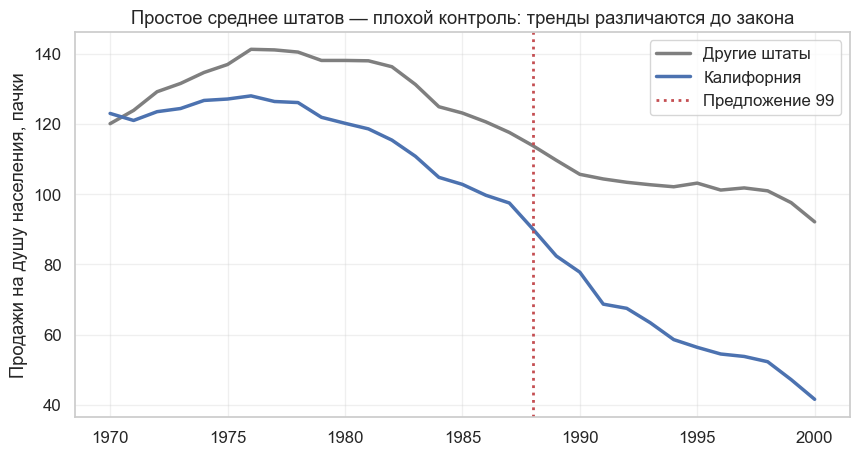

In [19]:
fig, ax = plt.subplots(figsize=(10, 5))
yearly = cigar.groupby(['year', 'california'])['cigsale'].mean().unstack()
ax.plot(yearly.index, yearly[False], color=GRAY, lw=2.5, label='Другие штаты')
ax.plot(yearly.index, yearly[True], color=BLUE, lw=2.5, label='Калифорния')
ax.axvline(1988, color=RED, ls=':', lw=2, label='Предложение 99')
ax.set_ylabel('Продажи на душу населения, пачки')
ax.set_title('Простое среднее штатов — плохой контроль: тренды различаются до закона')
ax.legend();

Жители Калифорнии покупают меньше сигарет, и снижение началось ещё до закона. После него падение как будто ускорилось, но график это не доказывает: среднее по штатам ведёт себя иначе и до 1988 года.

Составим из других штатов **фиктивный штат, повторяющий Калифорнию** до 1988 года, а потом посмотрим, что с ним стало.

Пусть есть $J+1$ единиц, единица 1 получила воздействие, а единицы $j=2,...,J+1$ образуют **донорский пул**. Есть $T$ периодов, из них $T_0$ до воздействия. Обозначим $Y^N_{jt}$ потенциальный исход без воздействия, $Y^I_{jt}$ — с воздействием. Эффект для единицы 1 при $t>T_0$ равен

$$
\tau_{1t} = Y^I_{1t} - Y^N_{1t}
$$

$Y^I_{1t}$ мы наблюдаем, а $Y^N_{1t}$ нужно оценить. Эффект определён для каждого периода, то есть может накапливаться или затухать.

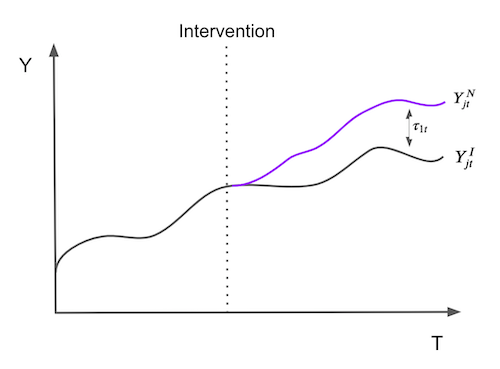

Комбинация единиц из пула может приблизить обработанную единицу лучше, чем любая единица в отдельности. Поэтому синтетический контроль определяется как взвешенное среднее:

$$
\hat{Y}^N_{1t} = \sum^{J+1}_{j=2} w_j Y_{jt}
$$

Веса подбираются по периоду до воздействия. Начнём с простейшего варианта: линейной регрессии. Сделаем штаты столбцами, а годы и признаки строками. Важно использовать только период до вмешательства. Признаки здесь в похожем масштабе; если бы это было не так, их следовало бы стандартизировать, иначе больший признак определял бы веса.

In [20]:
features_sc = ['cigsale', 'retprice']

inverted = (cigar.query('~after_treatment')
            .pivot(index='state', columns='year')[features_sc]
            .T)

y = inverted[CALIFORNIA].values
X = inverted.drop(columns=CALIFORNIA).values
print('Строк (целей подгонки):', X.shape[0], ' штатов-доноров:', X.shape[1])
inverted.iloc[:4, :5]

Строк (целей подгонки): 38  штатов-доноров: 38


state                  1           2           3           4           5
        year                                                            
cigsale 1970   89.800003  100.300003  123.000000  124.800003  120.000000
        1971   95.400002  104.099998  121.000000  125.500000  117.599998
        1972  101.099998  103.900002  123.500000  134.300003  110.800003
        1973  102.900002  108.000000  124.400002  137.899994  109.300003

In [21]:
weights_lr = LinearRegression(fit_intercept=False).fit(X, y).coef_
print(weights_lr.round(3))

sales = cigar.pivot(index='year', columns='state')['cigsale']
donors = sales.drop(columns=CALIFORNIA)
calif_synth_lr = donors.values.dot(weights_lr)
calif = sales[CALIFORNIA]

[-0.436 -1.038  0.679  0.078  0.339  1.213  0.143  0.555 -0.295  0.052
 -0.529  1.235 -0.549  0.437 -0.023 -0.266 -0.25  -0.667 -0.106 -0.145
  0.109  0.242 -0.328  0.594  0.243 -0.171 -0.02   0.14  -0.811  0.362
  0.519 -0.304  0.805 -0.318 -1.246  0.773 -0.055 -0.032]


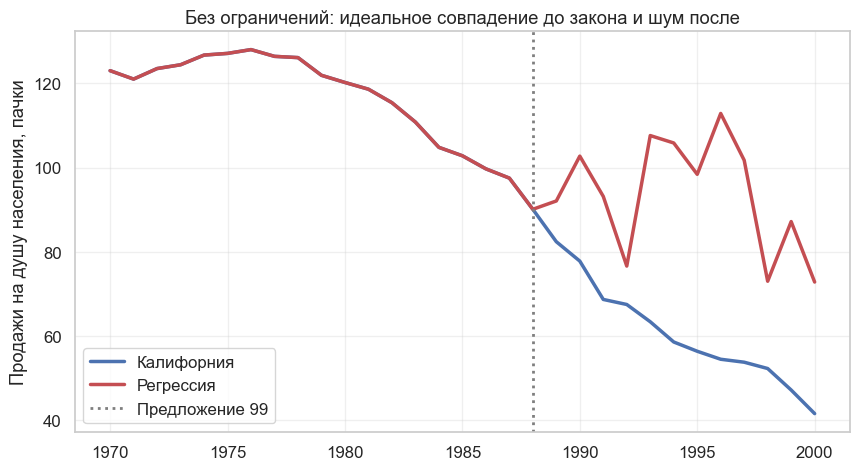

In [22]:
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.plot(calif.index, calif, color=BLUE, lw=2.5, label='Калифорния')
ax.plot(calif.index, calif_synth_lr, color=RED, lw=2.5, label='Регрессия')
ax.axvline(1988, color=GRAY, ls=':', lw=2, label='Предложение 99')
ax.set_ylabel('Продажи на душу населения, пачки')
ax.set_title('Без ограничений: идеальное совпадение до закона и шум после')
ax.legend();

Веса здесь бывают отрицательными и большими по модулю. Что-то не так. До вмешательства совпадение идеальное, а после ряд скачет. Причина ясна: у нас 38 строк и 38 доноров, столько же параметров, сколько условий. Модель просто решает систему уравнений, то есть переобучается.

Можно взять гребневую регрессию или лассо, но классическое решение другое: запретить экстраполяцию. Потребуем, чтобы веса были неотрицательны и суммировались в единицу. Тогда синтетический контроль будет выпуклой комбинацией доноров и останется внутри их диапазона:

$$
\hat{Y}^N_{1t} = \sum^{J+1}_{j=2} w_j Y_{jt}
$$

Веса $\pmb{W}=(w_2, ..., w_{J+1})$ минимизируют

$$
||\pmb{X}_1 - \pmb{X}_0 \pmb{W}|| = \bigg(\sum^k_{h=1}v_h \bigg(X_{h1} - \sum^{J+1}_{j=2} w_j X_{hj} \bigg)^2 \bigg)^{\frac{1}{2}}
$$

при условиях $w_j \geq 0$ и $\sum w_j = 1$. Здесь $v_h$ отражает важность признака $h$. Можно стандартизировать все признаки, а можно выбирать $V$ так, чтобы важнее были те, что лучше предсказывают $Y$. Для простоты возьмём равные $v_h$.

Задача решается оптимизатором SLSQP: ограничение на сумму задаётся функцией `lambda x: np.sum(x) - 1`, а границы весов от 0 до 1.

In [23]:
def loss_w(W, X, y):
    return np.sqrt(np.mean((y - X.dot(W)) ** 2))


def get_w(X, y):
    w_start = np.full(X.shape[1], 1 / X.shape[1])
    return fmin_slsqp(lambda W: loss_w(W, X, y), w_start, f_eqcons=lambda x: np.sum(x) - 1,
                      bounds=[(0.0, 1.0)] * len(w_start), disp=False)


calif_weights = get_w(X, y)
donor_weights = pd.Series(calif_weights, index=donors.columns)
print('Сумма весов:', round(calif_weights.sum(), 6))
print('Штаты с весом больше 1%:', donor_weights[donor_weights > 0.01].round(3).to_dict())

calif_synth = donors.values.dot(calif_weights)

Сумма весов: 1.0
Штаты с весом больше 1%: {5: 0.085, 21: 0.113, 22: 0.105, 23: 0.457, 34: 0.24}


Теперь ряд гладкий, а Калифорния описана всего пятью штатами. До закона контроль уже не повторяет её идеально, и это хороший признак: модель не переобучилась.

Разрыв в 2000 году: -24.8, в среднем за 1989–2000: -18.1


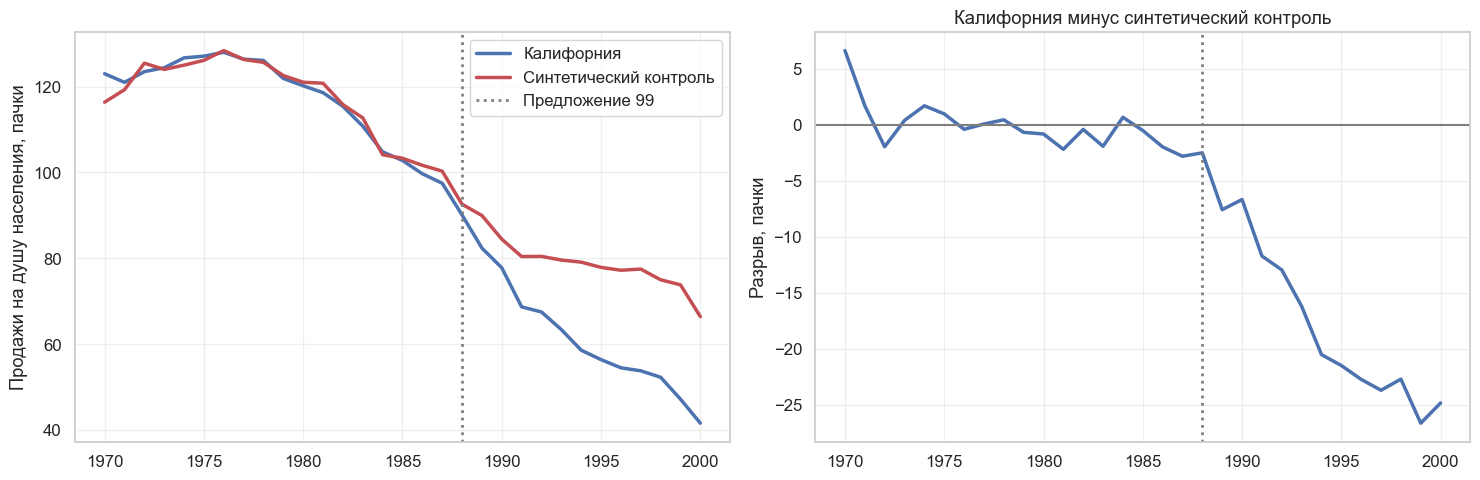

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(calif.index, calif, color=BLUE, lw=2.5, label='Калифорния')
axes[0].plot(calif.index, calif_synth, color=RED, lw=2.5, label='Синтетический контроль')
axes[0].axvline(1988, color=GRAY, ls=':', lw=2, label='Предложение 99')
axes[0].set_ylabel('Продажи на душу населения, пачки')
axes[0].legend()

gap = calif.values - calif_synth
axes[1].plot(calif.index, gap, color=BLUE, lw=2.5)
axes[1].axhline(0, color=GRAY)
axes[1].axvline(1988, color=GRAY, ls=':', lw=2)
axes[1].set_ylabel('Разрыв, пачки')
axes[1].set_title('Калифорния минус синтетический контроль')
plt.tight_layout()

post = calif.index > 1988
print(f'Разрыв в 2000 году: {gap[-1]:.1f}, в среднем за 1989–2000: {gap[post].mean():.1f}')

Эффект равен разнице $\hat{\tau}_{1t} = Y_{1t} - \hat{Y}^N_{1t}$. Он растёт со временем: к 2000 году продажи снизились почти на 25 пачек на человека.

Значим ли этот результат? Единица воздействия всего одна, поэтому применим идею **точного критерия Фишера**: поочерёдно делаем вид, что воздействие получил каждый штат.

|итерация|1|2|...|39|
|----|-|-|-|-|
|1|treated|0|0|0|
|2|0|treated|0|0|
|...|0|0|0|0|
|39|0|0|0|treated|

Получим по одному синтетическому контролю и оценке для каждого штата. Если эффект Калифорнии необычно велик на фоне этих **плацебо-эффектов**, это аргумент в пользу вмешательства.

In [25]:
def synthetic_gap(state, data=cigar, last_fit_year=1988):
    """Строит синтетический контроль для штата и возвращает его разрыв по годам."""
    fit = (data[data['year'] <= last_fit_year]
           .pivot(index='state', columns='year')[features_sc]
           .T)
    weights = get_w(fit.drop(columns=state).values, fit[state].values)
    return sales[state] - sales.drop(columns=state).values.dot(weights)


gaps = pd.DataFrame({state: synthetic_gap(state) for state in sales.columns})
gaps.iloc[:3, :5]

,1,2,3,4,5
year,,,,,
1970,-5.229416,-1.017167,6.622619,6.043383,11.425771
1971,-3.718197,-2.746091,1.706587,2.228855,5.282684
1972,-0.781330,-5.427321,-1.964882,0.257605,3.158567


Для Калифорнии это эффект воздействия, для других штатов — плацебо-эффект. Нарисуем всё вместе.

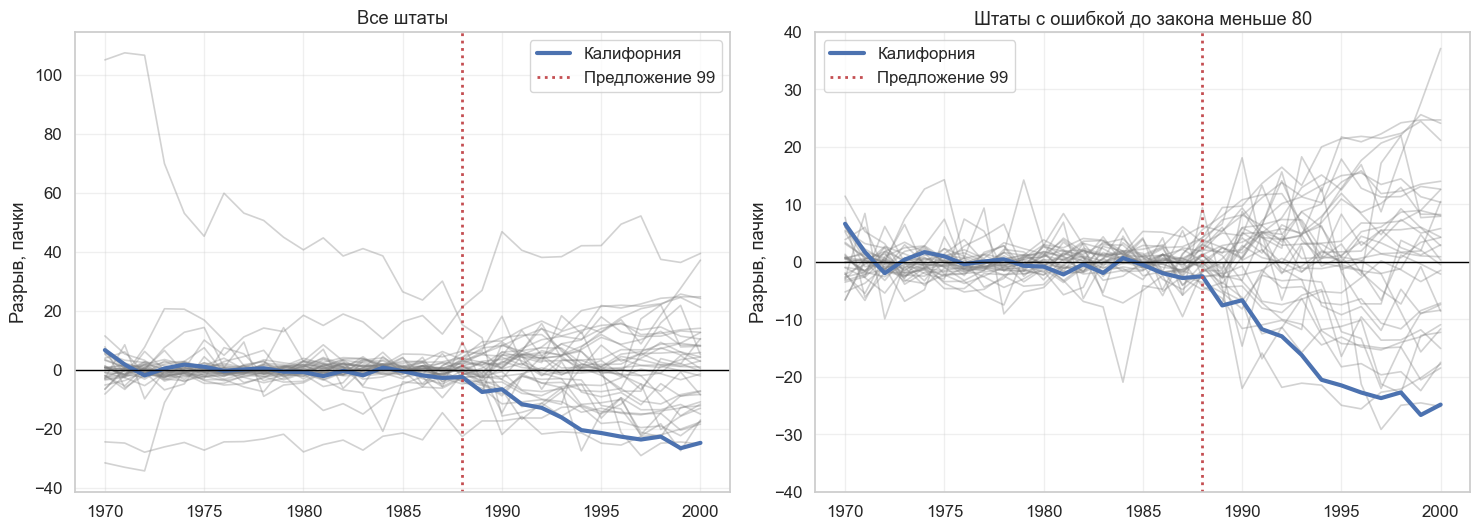

In [26]:
def plot_gaps(ax, states):
    for state in states:
        ax.plot(gaps.index, gaps[state], color=GRAY, alpha=0.35, lw=1.2)
    ax.plot(gaps.index, gaps[CALIFORNIA], color=BLUE, lw=3, label='Калифорния')
    ax.axvline(1988, color=RED, ls=':', lw=2, label='Предложение 99')
    ax.axhline(0, color='black', lw=1)
    ax.set_ylabel('Разрыв, пачки')
    ax.legend()


pre_error = (gaps[gaps.index <= 1988] ** 2).mean()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
plot_gaps(axes[0], sales.columns.drop(CALIFORNIA))
axes[0].set_title('Все штаты')
plot_gaps(axes[1], [s for s in sales.columns.drop(CALIFORNIA) if pre_error[s] < 80])
axes[1].set_title('Штаты с ошибкой до закона меньше 80')
axes[1].set_ylim(-40, 40)
plt.tight_layout()

После вмешательства разброс больше, чем до него. Это ожидаемо: веса подбирались по периоду до вмешательства. Некоторые штаты плохо описываются даже до него: если потребление очень высокое, никакая выпуклая комбинация других штатов до него не дотянется.

Такие штаты можно исключить, задав порог на ошибку до вмешательства:

$$
MSE = \frac{1}{T_0}\sum_{t \leq T_0}\big(Y_t - \hat{Y}^{Synth}_t\big)^2
$$

На правом графике эффект Калифорнии выглядит одним из самых крайних.

Если хотим p-value для односторонней гипотезы об уменьшении, надо найти долю штатов, включая саму Калифорнию, эффект которых не больше калифорнийского:

$$
PV=\frac{1}{N}\sum_j \mathcal{1}\{\hat{\tau}_j \leq \hat{\tau}_{Calif}\}
$$

Калифорния сама входит в перестановки. Без этого p-value могло бы быть нулевым, что в перестановочном тесте невозможно: минимум равен $1/N$.

Порог 80 произвольный. Поэтому [Абади (2021)](https://economics.mit.edu/sites/default/files/publications/jel.20191450.pdf) предлагают другой критерий без отбора: **отношение RMSPE** после и до вмешательства. Штат с плохой подгонкой получит большой знаменатель, и порог становится не нужен.

In [27]:
effects_2000 = gaps.loc[2000]
good_fit = pre_error < 80
ratio = np.sqrt((gaps[gaps.index > 1988] ** 2).mean()) / np.sqrt(pre_error)

rows = []
for name, values in [('Все штаты, эффект 2000 года', effects_2000), ('Ошибка до закона < 80, эффект 2000 года', effects_2000[good_fit])]:
    rows.append({'Критерий': name, 'Штатов': len(values), 'Не меньше эффекта': int((values <= values[CALIFORNIA]).sum()),
                 'p-value': (values <= values[CALIFORNIA]).mean()})
rows.append({'Критерий': 'Двустороннее по модулю, все штаты', 'Штатов': len(effects_2000), 'Не меньше эффекта': int((effects_2000.abs() >= abs(effects_2000[CALIFORNIA])).sum()),
             'p-value': (effects_2000.abs() >= abs(effects_2000[CALIFORNIA])).mean()})
rows.append({'Критерий': 'Отношение RMSPE, все штаты', 'Штатов': len(ratio), 'Не меньше эффекта': int((ratio >= ratio[CALIFORNIA]).sum()),
             'p-value': (ratio >= ratio[CALIFORNIA]).mean()})
pd.DataFrame(rows).round(3)

,Критерий,Штатов,Не меньше эффекта,p-value
0,"Все штаты, эффект 2000 года",39,2,0.051
1,"Ошибка до закона < 80, эффект 2000 года",35,2,0.057
2,"Двустороннее по модулю, все штаты",39,4,0.103
3,"Отношение RMSPE, все штаты",39,2,0.051


Калифорния занимает второе место из 39: штат 18 обогнал её и по эффекту 2000 года, и по отношению RMSPE. Отсюда p-value равно $2/39 = 0.051$ по всем штатам и $2/35 = 0.057$ с порогом на ошибку. В двустороннем варианте оно равно 0.10. Эффект не выглядит случайным, но при таком простом наборе признаков он формально не достигает уровня 5%.

Обратите внимание, что в простой записи легко забыть про саму Калифорнию и получить $1/35 = 0.029$: это вдвое занижает p-value. В статье Абади и соавторов используется больше признаков, и Калифорния там лидирует. Выбор признаков заметно влияет на вывод.

Проверим устойчивость ещё двумя способами. Первый — **плацебо во времени**: делаем вид, что закон приняли раньше, и подбираем веса только по годам до этой даты. Подвигайте год. Второй — выбрасывание доноров по одному.

In [28]:
def plot_time_placebo(ax, year):
    placebo_gap = synthetic_gap(CALIFORNIA, last_fit_year=year)
    ax.plot(placebo_gap.index, placebo_gap, color=BLUE, lw=2.5, label='Разрыв')
    ax.axvline(year, color=GREEN, ls='--', lw=2, label=f'Ложная дата {year}')
    ax.axvline(1988, color=RED, ls=':', lw=2, label='Предложение 99')
    ax.axhline(0, color='black', lw=1)
    ax.set_ylim(-40, 15)
    ax.set_title(f'Разрыв в 1988 году: {placebo_gap.loc[1988]:.1f}', fontsize=12)
    ax.set_ylabel('Разрыв, пачки')


def placebo_demo(year=1980):
    fig, ax = plt.subplots(figsize=(8.5, 4.3))
    plot_time_placebo(ax, year)
    ax.legend(fontsize=10)
    plt.show()


interact(placebo_demo, year=IntSlider(value=1980, min=1976, max=1988, step=1, description='Год'));

Статичная версия для трёх дат и выбрасывание доноров.

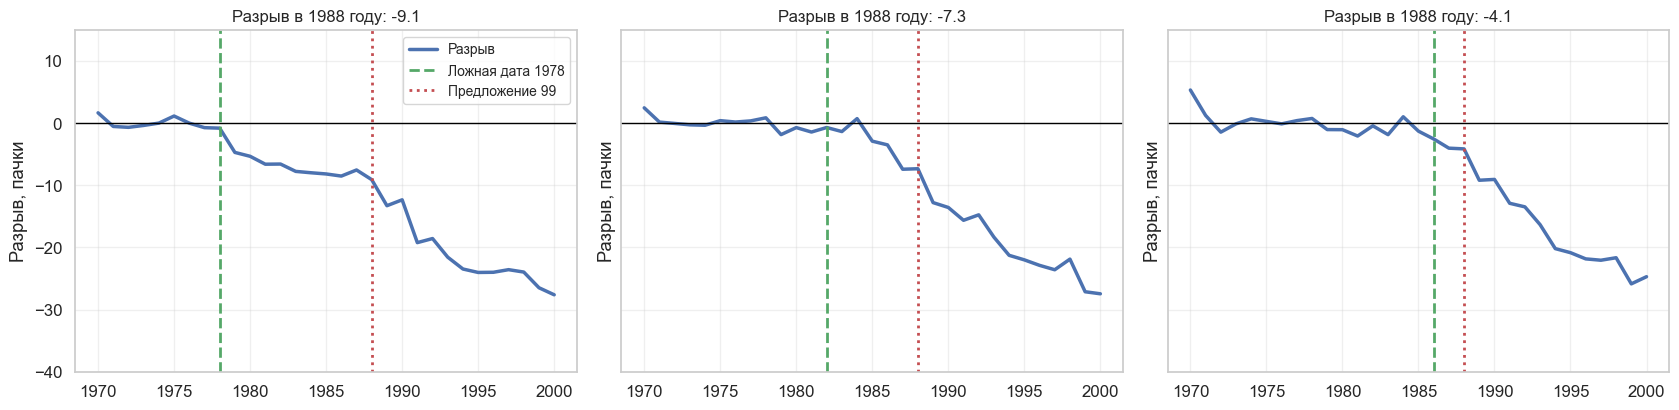

Эффект 2000 года без одного донора: {5: np.float64(-25.4), 21: np.float64(-26.3), 22: np.float64(-25.8), 23: np.float64(-28.4), 34: np.float64(-25.7)}


In [29]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.3), sharey=True)
for ax, year in zip(axes, [1978, 1982, 1986]):
    plot_time_placebo(ax, year)
axes[0].legend(fontsize=10)
plt.tight_layout()
plt.show()

leave_one_out = {}
for state in donor_weights[donor_weights > 0.05].index:
    reduced = cigar.query('state != @state')
    fit = reduced[reduced['year'] <= 1988].pivot(index='state', columns='year')[features_sc].T
    weights = get_w(fit.drop(columns=CALIFORNIA).values, fit[CALIFORNIA].values)
    leave_one_out[state] = calif.loc[2000] - sales.drop(columns=[CALIFORNIA, state]).loc[2000].values.dot(weights)
print('Эффект 2000 года без одного донора:', {k: round(v, 1) for k, v in leave_one_out.items()})

Эффект 2000 года устойчив к выбрасыванию доноров: от -25.4 до -28.4. Даже без штата с весом 46% он сохраняется.

Плацебо во времени настораживает больше. При ложной дате 1978 или 1982 разрыв к 1988 году уже равен -9 и -7, хотя закона ещё нет. Значит, продажи в Калифорнии снижались быстрее доноров до закона, и часть разрыва может быть не связана с Предложением 99: в штате могла быть своя динамика. После 1988 года разрыв всё равно растёт заметно быстрее. Поэтому вывод такой: закон, вероятно, снизил продажи, но 25 пачек лучше считать верхней оценкой.

## Панельные данные и фиксированные эффекты

Propensity score, регрессия и мэтчинг опираются на условную несмешиваемость:

$$
(Y_0, Y_1) \perp T | X
$$

Все конфаундеры должны быть измерены, а это не всегда возможно. Классический пример — влияние брака на заработок мужчин. Женатые зарабатывают больше, но причинно ли это? Образование можно измерить, а привлекательность или интеллект так точно не измерить.

Инструменты подходят не всегда, поэтому воспользуемся структурой панельных данных. Мы отслеживаем один и тот же объект несколько периодов. Брак (воздействие) включается в периоды 3 и 4, и в те же периоды растёт доход (исход). Привлекательность, неизмеряемый фактор, постоянна. Это смелое, но разумное предположение, если период составляет несколько лет.

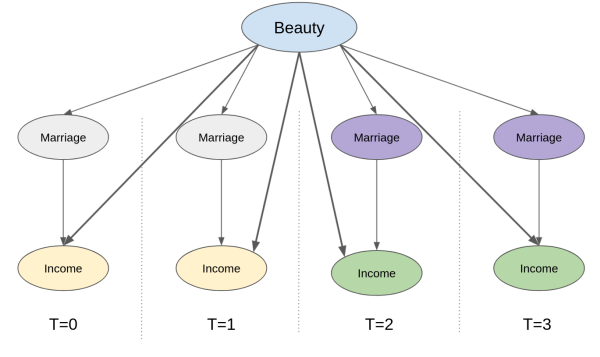

Отслеживая единицу во времени, мы уже контролируем всё, что в ней постоянно. Рост дохода не может быть вызван привлекательностью, раз она не менялась.

Постоянные конфаундеры можно рассматривать как атрибуты единицы. Это равносильно добавлению узла единицы в граф. Контроль этого узла закрывает все такие пути.

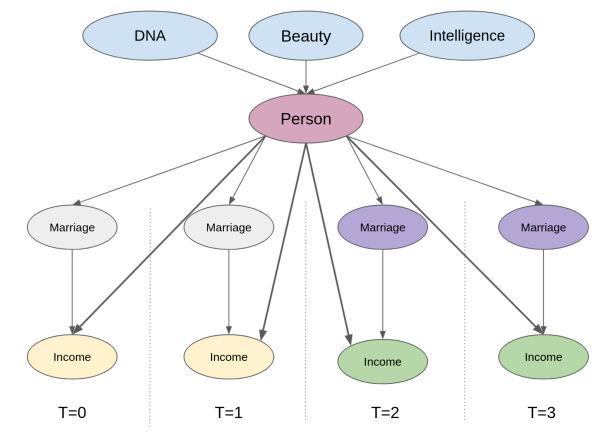

Механика проста: создаём бинарные переменные для каждого человека и добавляем в модель. Регрессия оценит влияние брака **при фиксированном человеке**. Такая модель называется моделью с фиксированными эффектами.

### Фиксированные эффекты

Используем панель Ваеллы и Вербека: 545 мужчин за 1980–1987 годы. Переменные `married` и логарифм зарплаты `lwage` есть для каждого человека `nr` и года, а также контроли: часы работы, образование и другие.

In [30]:
panel = wage_panel.load()
panel.head()

,nr,year,black,exper,hisp,hours,married,educ,union,lwage,expersq,occupation
0,13,1980,0,1,0,2672,0,14,0,1.197540,1,9
1,13,1981,0,2,0,2320,0,14,1,1.853060,4,9
2,13,1982,0,3,0,2940,0,14,0,1.344462,9,9
3,13,1983,0,4,0,2960,0,14,0,1.433213,16,9
4,13,1984,0,5,0,3071,0,14,0,1.568125,25,5


Модель с фиксированными эффектами имеет вид

$$
y_{it} = \beta X_{it} + \gamma U_i + e_{it}
$$

где $y_{it}$ — исход индивида $i$ в момент $t$, $X_{it}$ — меняющиеся переменные, а $U_i$ — ненаблюдаемые постоянные. Времени в индексе $U_i$ нет.

На практике бинарные переменные не добавляют: при миллионе клиентов это миллион столбцов. Используем теорему Фриша — Во — Ловелла из лекции 2.08. Чтобы получить $\hat{\beta_1}$ в модели

$$
\hat{Y} = \hat{\beta_1} X_1 + \hat{\beta_2} X_2,
$$

можно:

1. регрессировать $Y$ на $X_2$;
2. регрессировать $X_1$ на $X_2$;
3. получить остатки $\tilde{X}_1$ и $\tilde{Y}$;
4. регрессировать $\tilde{Y}$ на $\tilde{X}_1$.

Здесь $X_2$ — бинарные переменные людей. Регрессия на бинарные переменные — это просто средние по группам. Проверим на годах.

In [31]:
mod = smf.ols('lwage ~ C(year)', data=panel).fit()
print(mod.params.round(4).head(3).to_dict())
print('Предсказание 1981 года:', round(mod.params['Intercept'] + mod.params['C(year)[T.1981]'], 4))
print(panel.groupby('year')['lwage'].mean().round(4).head(3).to_dict())

{'Intercept': 1.3935, 'C(year)[T.1981]': 0.1194, 'C(year)[T.1982]': 0.1782}
Предсказание 1981 года: 1.5129
{1980: 1.3935, 1981: 1.5129, 1982: 1.5717}


Значит, вычесть из переменных среднее по человеку — то же самое, что взять остатки от регрессии на его бинарные переменные. Получаем процедуру:

1. Вычитаем средние по индивиду: $\ddot{Y}_{it} = Y_{it} - \bar{Y}_i$ и $\ddot{X}_{it} = X_{it} - \bar{X}_i$.
2. Регрессируем $\ddot{Y}_{it}$ на $\ddot{X}_{it}$.

При этом $U_i$ исчезает, потому что $\bar{U_i}=U_i$:

$$
\begin{align}
Y_{it} & = \beta X_{it} + \gamma U_i + e_{it} \\
\bar{Y}_{i} & = \beta \bar{X}_{i} + \gamma \bar{U}_i + \bar{e}_{i} \\
\end{align}
$$

Вычитая, получаем:

$$
\begin{align}
(Y_{it} - \bar{Y}_{i}) & = \beta(X_{it} - \bar{X}_{i}) + (\gamma U_i - \gamma U_i) + (e_{it} - \bar{e}_{i}) \\
\ddot{Y}_{it} & = \beta \ddot{X}_{it} + \ddot{e}_{it} \\
\end{align}
$$

Исчезают все постоянные во времени переменные, а не только ненаблюдаемые. Поэтому их нельзя включить: они будут линейной комбинацией бинарных переменных людей. Проверим, что не меняется внутри человека.

In [32]:
panel.drop(columns='nr').groupby(panel['nr']).std().sum().round(1)

year            1335.0
black              0.0
exper           1335.0
hisp               0.0
hours         203098.2
married          140.4
educ               0.0
union            106.5
lwage            173.9
expersq        17608.2
occupation       739.2
dtype: float64

`black`, `hisp` и `educ` постоянны. Также мы не берём `occupation`, потому что профессия может быть медиатором влияния брака. По той же логике под вопросом `union` и `hours`: брак может менять часы работы. Оставим их, как в источнике, а ниже посмотрим на оценку без них.

Сделаем fixed effects вручную.

In [33]:
Y_name = 'lwage'
T_name = 'married'
X_names = [T_name, 'expersq', 'union', 'hours']

mean_data = panel.groupby('nr')[X_names + [Y_name]].mean()
demeaned_data = panel.set_index('nr')[X_names + [Y_name]] - mean_data

mod = smf.ols(f"{Y_name} ~ {' + '.join(X_names)}", data=demeaned_data).fit()
print(mod.summary().tables[1])

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept  -6.852e-17      0.005  -1.35e-14      1.000      -0.010       0.010
married        0.1147      0.017      6.756      0.000       0.081       0.148
expersq        0.0040      0.000     21.958      0.000       0.004       0.004
union          0.0784      0.018      4.261      0.000       0.042       0.115
hours       -8.46e-05   1.25e-05     -6.744      0.000      -0.000      -6e-05


Брак повышает зарплату на $e^{0.1147} - 1 = 12\%$, если верить, что фиксированные эффекты убрали всё смещение. SE здесь занижена: наблюдения одного человека зависимы, а при вычитании средних потеряны степени свободы. Поэтому нужны кластеризованные ошибки, и вручную это неудобно. Используем `PanelOLS` из `linearmodels` с аргументом `cluster_entity=True`.

In [34]:
panel_index = panel.set_index(['nr', 'year'])

result = (PanelOLS.from_formula('lwage ~ expersq + union + married + hours + EntityEffects', data=panel_index)
          .fit(cov_type='clustered', cluster_entity=True))
print(result.summary.tables[1])

                             Parameter Estimates                              
            Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
------------------------------------------------------------------------------
expersq        0.0040     0.0002     16.552     0.0000      0.0035      0.0044
union          0.0784     0.0236     3.3225     0.0009      0.0322      0.1247
married        0.1147     0.0220     5.2213     0.0000      0.0716      0.1577
hours       -8.46e-05   2.22e-05    -3.8105     0.0001     -0.0001  -4.107e-05


Коэффициент тот же, 0.1147, а SE выросла с 0.017 до 0.022.

### Визуализация фиксированных эффектов

Рассмотрим другой пример. Отдел маркетинга тратит больше на билборды в городах с низкими покупками. Регрессия на этих данных покажет, что больше затрат означает меньше покупок: инвестиции смещены к слабым регионам.

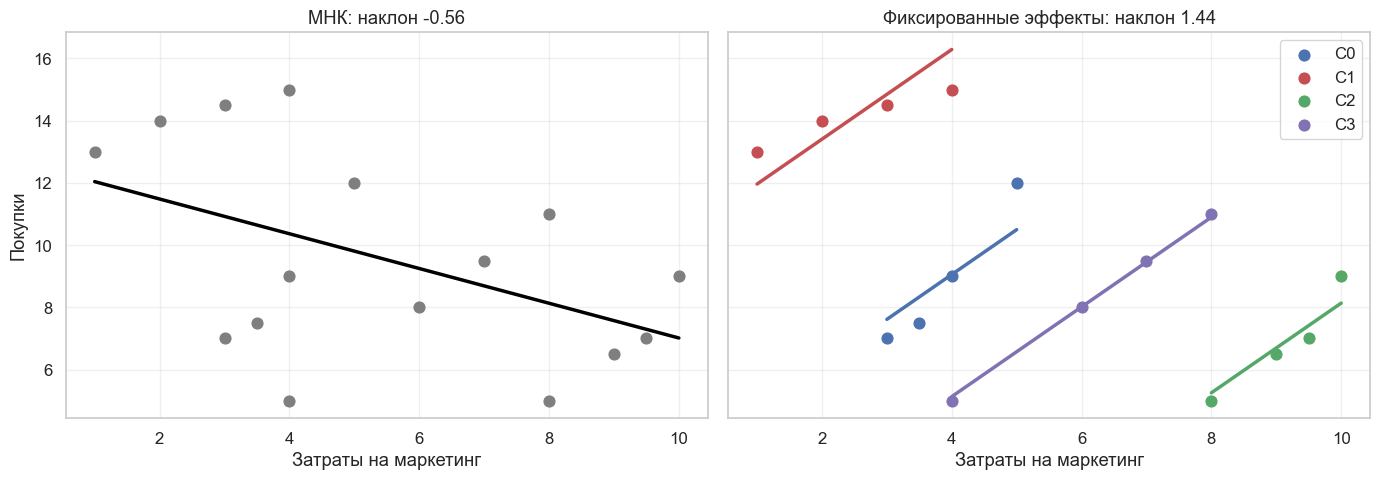

In [35]:
toy_panel = pd.DataFrame({
    'mkt_costs': [5, 4, 3.5, 3, 10, 9.5, 9, 8, 4, 3, 2, 1, 8, 7, 6, 4],
    'purchase': [12, 9, 7.5, 7, 9, 7, 6.5, 5, 15, 14.5, 14, 13, 11, 9.5, 8, 5],
    'city': ['C0', 'C0', 'C0', 'C0', 'C2', 'C2', 'C2', 'C2', 'C1', 'C1', 'C1', 'C1', 'C3', 'C3', 'C3', 'C3']
})

pooled = smf.ols('purchase ~ mkt_costs', data=toy_panel).fit()
fe = smf.ols('purchase ~ mkt_costs + C(city)', data=toy_panel).fit()
toy_panel['y_hat'] = fe.fittedvalues
city_colors = dict(zip(sorted(toy_panel['city'].unique()), [BLUE, RED, GREEN, '#8172B3']))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)
axes[0].scatter(toy_panel['mkt_costs'], toy_panel['purchase'], color=GRAY, s=60)
ordered = toy_panel.sort_values('mkt_costs')
axes[0].plot(ordered['mkt_costs'], pooled.predict(ordered), color='black', lw=2.5)
axes[0].set_title(f"МНК: наклон {pooled.params['mkt_costs']:.2f}")

for city, part in toy_panel.groupby('city'):
    axes[1].scatter(part['mkt_costs'], part['purchase'], color=city_colors[city], s=60, label=city)
    axes[1].plot(part['mkt_costs'], part['y_hat'], color=city_colors[city], lw=2.5)
axes[1].set_title(f"Фиксированные эффекты: наклон {fe.params['mkt_costs']:.2f}")
axes[1].legend()
axes[0].set_xlabel('Затраты на маркетинг')
axes[1].set_xlabel('Затраты на маркетинг')
axes[0].set_ylabel('Покупки')
plt.tight_layout()

Модель с фиксированными эффектами учитывает постоянные характеристики города. Она подгоняет **отдельную линию на каждый город**, и эти линии параллельны. Наклон положителен: внутри города больше затрат означает больше покупок.

Параллельность означает, что **модель предполагает одинаковый эффект во всех единицах**. Если эффект различается, модель усредняет его с весами, зависящими от вариации воздействия внутри единиц.

### Временные эффекты

Бинарные переменные индивидов контролируют постоянные характеристики индивидов. Бинарные переменные времени контролируют то, что меняется во времени, но одинаково для всех. Пример — инфляция: номинальные зарплаты растут у всех. Если за эти годы больше мужчин вступили в брак, а зарплаты тоже выросли, то брак будет коррелировать с зарплатой просто из-за времени. В `linearmodels` достаточно добавить `TimeEffects`. Здесь мы используем `expersq`, а не `exper`: с временными эффектами опыт, растущий у всех на год за год, неотличим от них.

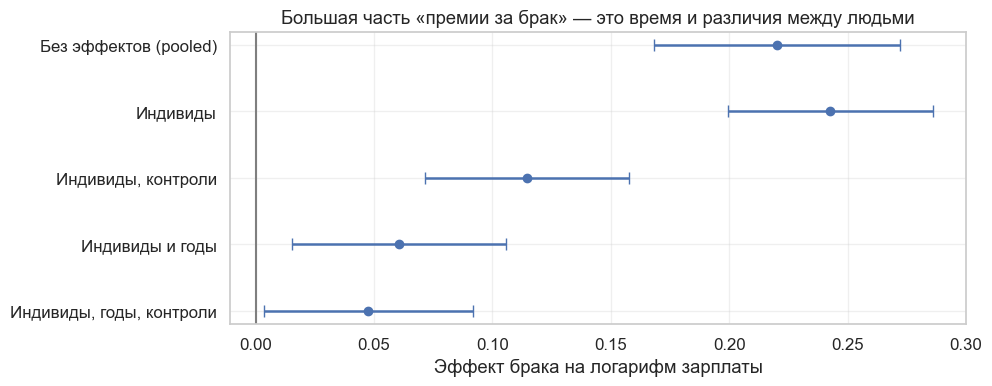

,Модель,Оценка,SE,ДИ 2.5%,ДИ 97.5%
0,Без эффектов (pooled),0.2203,0.0265,0.1684,0.2722
1,Индивиды,0.2427,0.0221,0.1994,0.2860
2,"Индивиды, контроли",0.1147,0.0220,0.0716,0.1577
3,Индивиды и годы,0.0606,0.0230,0.0155,0.1056
4,"Индивиды, годы, контроли",0.0476,0.0226,0.0034,0.0919


In [36]:
specifications = {
    'Без эффектов (pooled)': 'lwage ~ 1 + married',
    'Индивиды': 'lwage ~ married + EntityEffects',
    'Индивиды, контроли': 'lwage ~ married + expersq + union + hours + EntityEffects',
    'Индивиды и годы': 'lwage ~ married + EntityEffects + TimeEffects',
    'Индивиды, годы, контроли': 'lwage ~ married + expersq + union + hours + EntityEffects + TimeEffects',
}

rows = []
for name, formula in specifications.items():
    fit = PanelOLS.from_formula(formula, data=panel_index, drop_absorbed=True).fit(cov_type='clustered', cluster_entity=True)
    low, high = fit.conf_int().loc['married']
    rows.append({'Модель': name, 'Оценка': fit.params['married'], 'SE': fit.std_errors['married'], 'ДИ 2.5%': low, 'ДИ 97.5%': high})
married_table = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(9.5, 3.8))
y_pos = np.arange(len(married_table))[::-1]
ax.errorbar(married_table['Оценка'], y_pos, xerr=1.96 * married_table['SE'], fmt='o', color=BLUE, capsize=4, lw=1.8)
ax.axvline(0, color=GRAY)
ax.set_yticks(y_pos, married_table['Модель'])
ax.set_xlabel('Эффект брака на логарифм зарплаты')
ax.set_title('Большая часть «премии за брак» исчезает при учёте лет')
plt.show()
married_table.round(4)

Индивидуальные эффекты сами по себе почти не изменили оценку: 0.24 против 0.22. Основной вклад дают годы: с ними оценка падает до 0.06, то есть большая часть связи — это общий рост зарплат, идущий одновременно с вступлением в брак. Контроли снижают её ещё до 0.048, но они, как мы говорили, могут быть медиаторами.

Для `married` в модели с годами оценка значима на уровне 5%: p = 0.035 при кластеризации по людям. В исходной версии использовалась двойная кластеризация по людям и годам, она даёт SE 0.018 и p = 0.007. Но кластеров по годам всего 8, и такой SE ненадёжен, поэтому мы используем более консервативный вариант.

Проверим, не следует ли брак за ростом зарплаты. Для этого добавим в модель будущий брак: при верной модели будущее воздействие не должно влиять на текущий исход.

In [37]:
leads = panel.sort_values(['nr', 'year']).assign(
    married_next=lambda d: d.groupby('nr')['married'].shift(-1),
    married_next2=lambda d: d.groupby('nr')['married'].shift(-2)).dropna(subset=['married_next', 'married_next2'])

lead_model = (PanelOLS.from_formula('lwage ~ married + married_next + married_next2 + EntityEffects + TimeEffects',
                                    data=leads.set_index(['nr', 'year']))
              .fit(cov_type='clustered', cluster_entity=True))
print(lead_model.summary.tables[1])

                               Parameter Estimates                               
               Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
---------------------------------------------------------------------------------
married           0.0609     0.0309     1.9708     0.0489      0.0003      0.1215
married_next      0.0001     0.0272     0.0049     0.9961     -0.0531      0.0534
married_next2    -0.0102     0.0277    -0.3695     0.7118     -0.0645      0.0441


Будущий брак не связан с текущей зарплатой: коэффициенты при `married_next` и `married_next2` близки к нулю. Это аргумент против того, что брак просто следует за ростом зарплаты. Коэффициент при текущем браке остался около 0.06.

### Когда панельные данные не помогут

Фиксированные эффекты — сильный инструмент, если нет случайных данных и хороших инструментов. Но это не панацея.

* **Меняющиеся конфаундеры.** Эффекты убирают только постоянные характеристики. Если человек становится умнее, получает лучшую работу и чаще вступает в брак, смещение останется.
* **Обратная причинность.** Возможно, не брак влияет на доход, а рост дохода повышает шансы на брак. Доход меняется во времени, так что эффекты этого не контролируют. Тест с будущими значениями помогает, но не всё исключает.
* **Плохие контроли.** Правила из лекции 2.08 работают и здесь: `hours` и `union` могут быть следствием брака.
* **Мало вариации.** Эффект оценивается только по тем, у кого воздействие менялось. Постоянно женатые и постоянно холостые в оценку не вносят вклад.

Связь с diff-in-diff прямая: DiD с двумя группами и двумя периодами — это модель с фиксированными эффектами групп и времени.

## Заключение

| Метод | Что оценивает | Ключевое предположение | Что можно проверить |
| :--- | :--- | :--- | :--- |
| IPTW | ATE или ATT | Нет неизмеренных конфаундеров, есть перекрытие | Баланс, распределение скоров |
| Мэтчинг | Обычно ATT | То же | Баланс по признакам |
| Diff-in-Diff | ATT | Параллельные тренды | Тренды до вмешательства |
| Синтетический контроль | Эффект на одну единицу по времени | Веса переносятся на период после воздействия | Плацебо по единицам и времени, отбрасывание доноров |
| Фиксированные эффекты | Эффект у тех, у кого воздействие менялось | Конфаундеры постоянны во времени | Будущие значения воздействия |

Главное из лекции:

* propensity score сокращает признаки до одного числа, но не защищает от неизмеренных конфаундеров;
* перед оценкой IPTW и мэтчинга нужно смотреть перекрытие и баланс, а не только итоговое число;
* если воздействие назначено группам, SE на уровне наблюдений занижены, и нужно считать кластеры;
* если единиц мало, вывод строится на плацебо, а p-value в перестановках не может быть меньше $1/N$;
* самые важные предположения всех методов на данных не проверяются, их нужно обосновывать.